# Presentation of the data sampled along Oder river

In [7]:
import pandas as pd
import os
from matplotlib import pyplot as plt
import numpy as np
from scripts.plot_aux import plot_background_map, plot_spectra_labels
import geopandas as gpd
from matplotlib.colors import Normalize

MAP_CRS = "EPSG:3035"
plt.style.use('dark_background')

In [2]:
dated_profiles = os.listdir("local/profiles/")
profiles = {}
for dir in dated_profiles:
    profile = pd.read_csv(f"local/profiles/{dir}")
    date = dir.split(".")[0]
    profiles[date] = profile

In [3]:
def calculate_ndci(profile, median_window=51):
    ndci = (profile["B05 VNIR"] - profile["B04 Red"]) / (profile["B05 VNIR"] + profile["B04 Red"])
    ndci_median = ndci.rolling(median_window, center=True, min_periods=1).median()
    return ndci_median

def calculate_cari(profile, median_window=51):
    cari = (profile["B03 Green"] - profile["B02 Blue"]) / (profile["B03 Green"] + profile["B02 Blue"])
    cari_median = cari.rolling(median_window, center=True, min_periods=1).median()
    return cari_median

### Spectral characteristics

#### Above Warta confluence (220-230 km)

In [6]:
band_names10 = ["B02 Blue", "B03 Green", "B04 Red", "B08 VNIR"]
band_names20 = ["B05 VNIR", "B06 VNIR", "B07 VNIR", "B08a VNIR", "B11 SWIR", "B12 SWIR", "SCL SceneClassification"]
band_names = band_names10 + band_names20[:-1] # Exclude SCL from band_names for sampling
band_wavelengths = {
    "B02 Blue": 490,
    "B03 Green": 560,
    "B04 Red": 665,
    "B05 VNIR": 705,
    "B06 VNIR": 740,
    "B07 VNIR": 783,
    "B08 VNIR": 842,
    "B08a VNIR": 865,
    "B11 SWIR": 1610,
    "B12 SWIR": 2190
}
band_names = sorted(band_names, key=lambda band: band_wavelengths[band])
wavelengths = [band_wavelengths[band] for band in band_names]

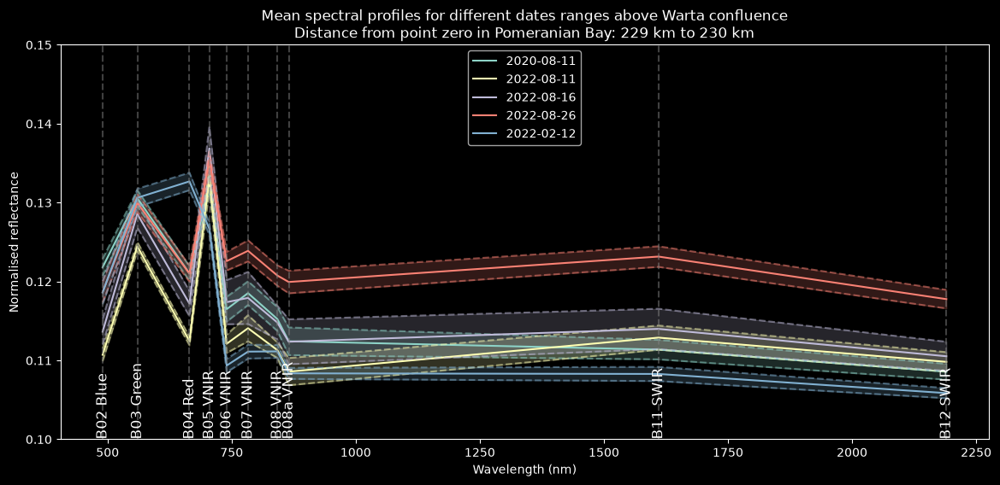

In [21]:
domain_from, domain_to = 229, 230

fig, ax = plt.subplots(figsize=(14, 6))
for date in profiles:
    if date == "20220905":
        continue # messy data, let us skip it for now
    year, month, day = date[0:4], date[4:6], date[6:8]
    profile = profiles[date]
    profile = profile[(profile["distance_km"] >= domain_from) & (profile["distance_km"] <= domain_to)]
    if profile.empty:
        continue
    means = []
    stds = []
    for band in band_names:
        band_values = profile[band].values / 10_000
        means.append(band_values.mean())
        stds.append(band_values.std())
    means = np.array(means)
    stds = np.array(stds)
    lower = means - stds
    upper = means + stds
    line, = ax.plot(wavelengths, means, label=f'{year}-{month}-{day}')
    color = line.get_color()
    ax.fill_between(wavelengths, lower, upper, color=color, alpha=0.2)
    ax.plot(wavelengths, lower, color=color, alpha=0.5, linestyle='--')
    ax.plot(wavelengths, upper, color=color, alpha=0.5, linestyle='--')
plt.ylim(0.1, 0.15)
plot_spectra_labels(wavelengths, band_names, ax)
plt.title(f"Mean spectral profiles for different dates ranges above Warta confluence\nDistance from point zero in Pomeranian Bay: {domain_from} km to {domain_to} km")
plt.legend()

### NDCI

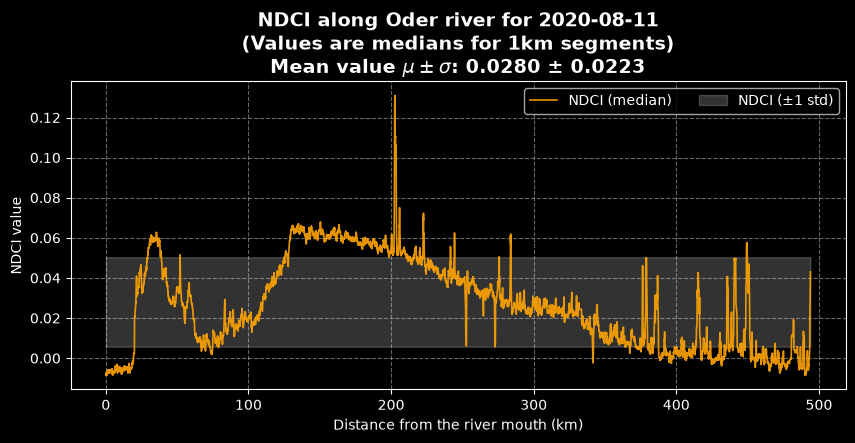

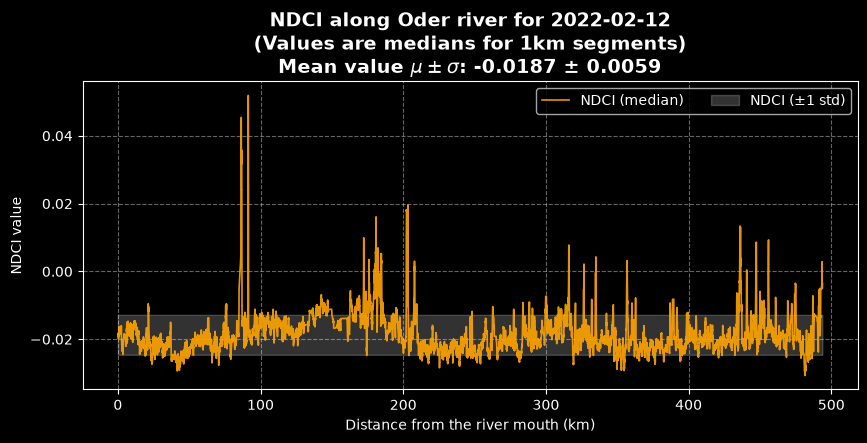

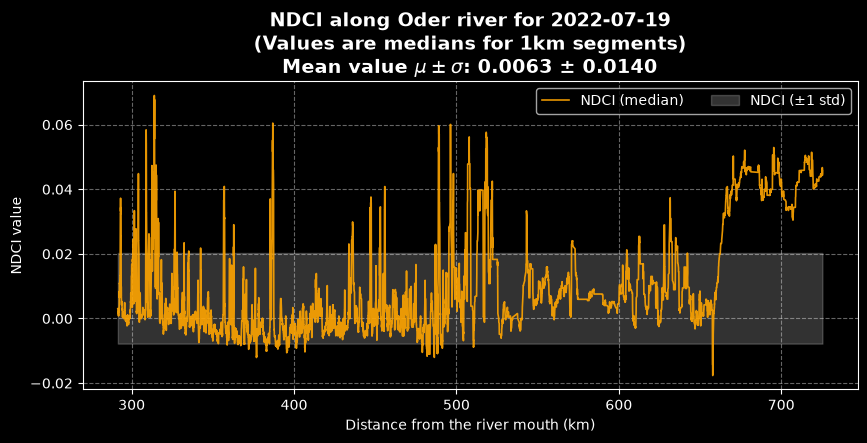

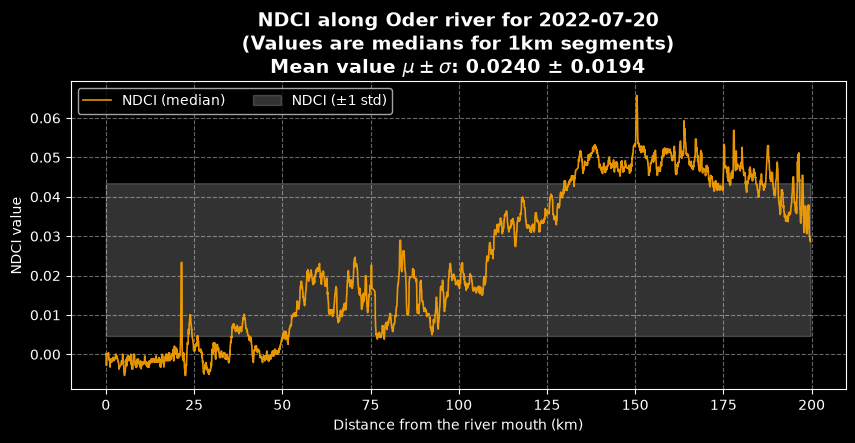

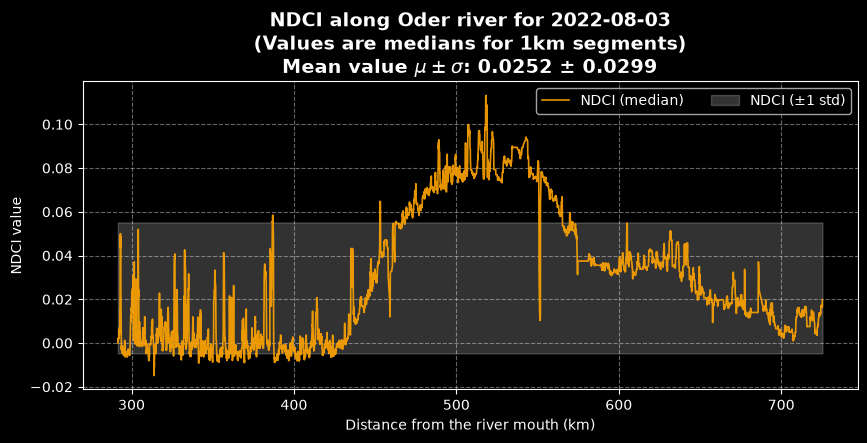

...

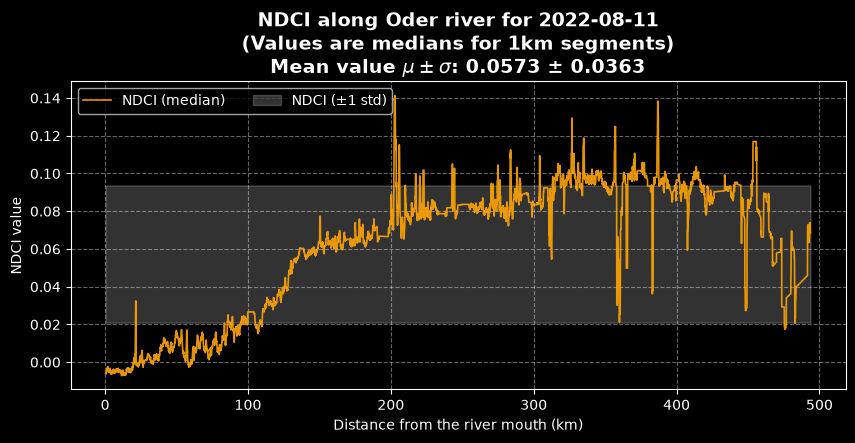

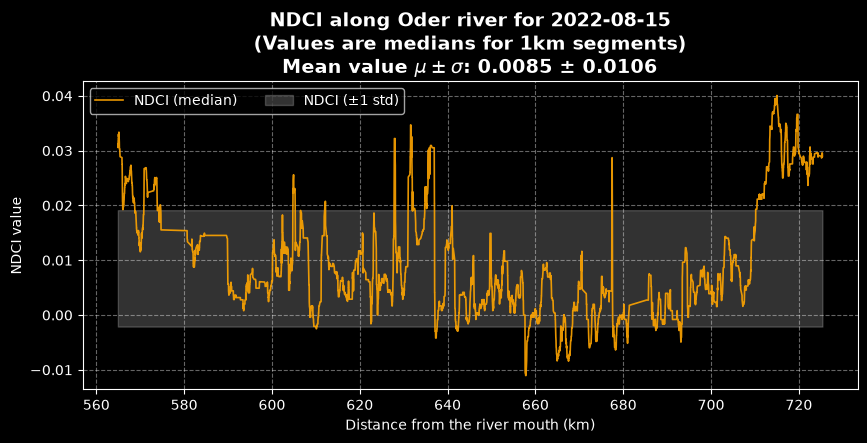

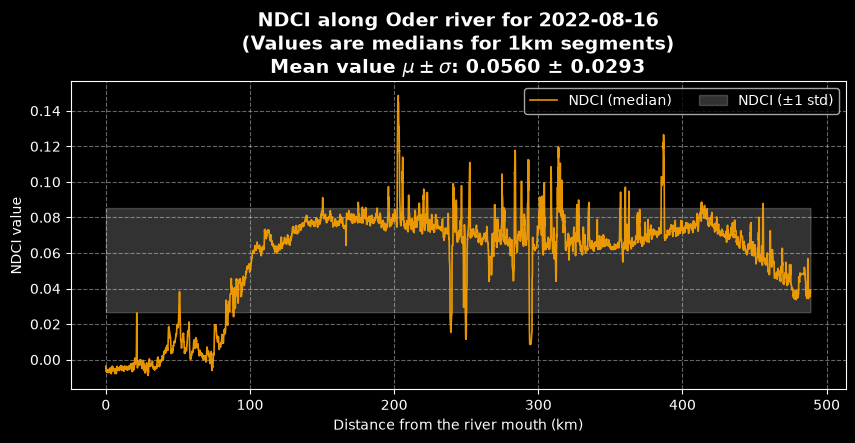

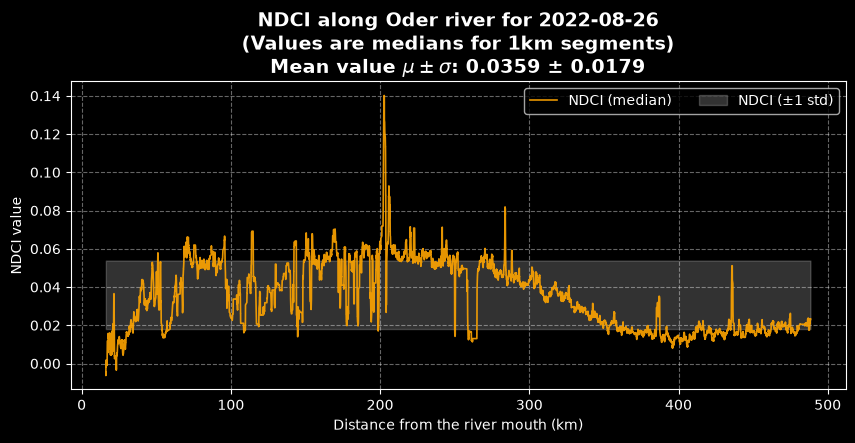

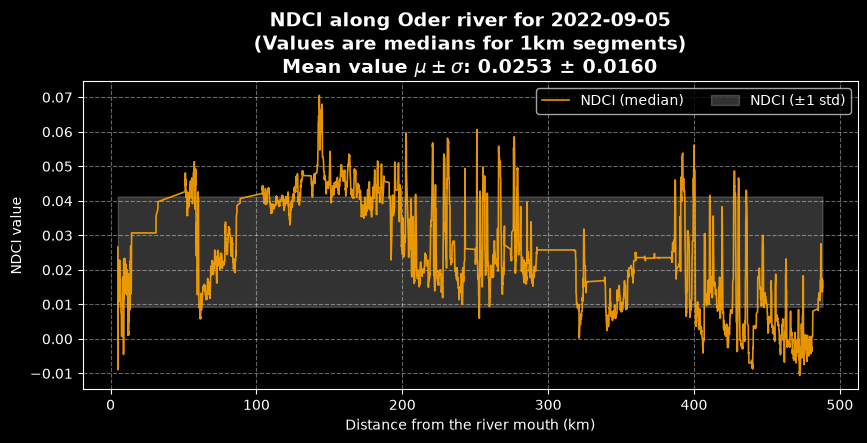

In [4]:
for date in sorted(profiles.keys()):
    profile = profiles[date]
    year, month, day = date[0:4], date[4:6], date[6:8]

    fig, ax = plt.subplots(figsize=(10, 4))
    cari_median = calculate_ndci(profile=profile, median_window=51)
    cari_mean = np.mean(cari_median)
    cari_std = np.std(cari_median)

    ax.plot(
        profile["distance_km"],
        cari_median,
        label="NDCI (median)",
        color="orange",
        linewidth=1.2,
        alpha=0.9
    )

    ax.fill_between(
        profile["distance_km"],
        cari_mean - cari_std,
        cari_mean + cari_std,
        color="white",
        alpha=0.2,
        label="NDCI (±1 std)"
    )

    ax.set_title(
        "NDCI along Oder river for " + f"{year}-{month}-{day}\n(Values are medians for 1km segments)" +
        "\nMean value $\\mu\\pm\\sigma$: " + f"{cari_mean:.4f} ± {cari_std:.4f}",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Distance from the river mouth (km)")
    ax.set_ylabel("NDCI value")
    # ax.set_ylim(-0.02, 0.15)

    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(ncols=2)

    plt.show()

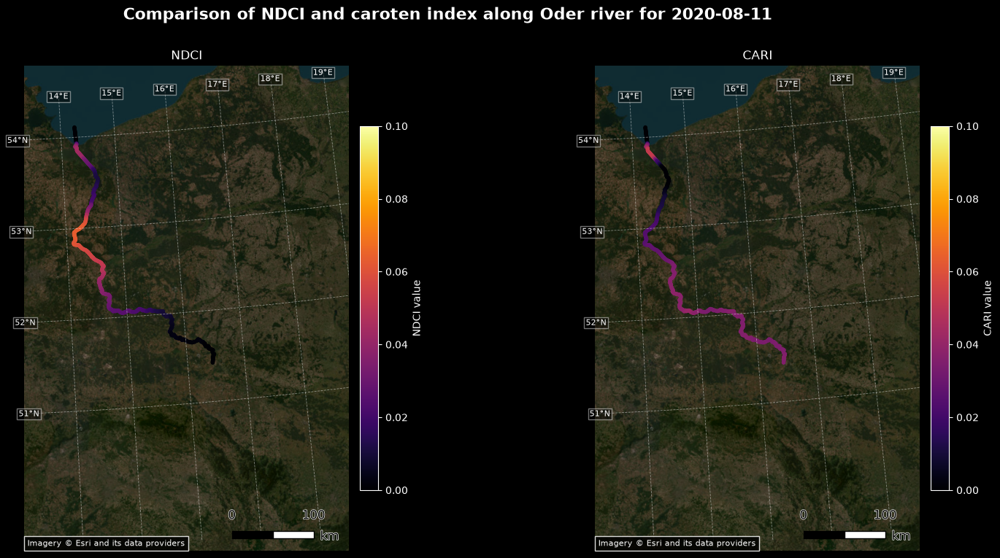

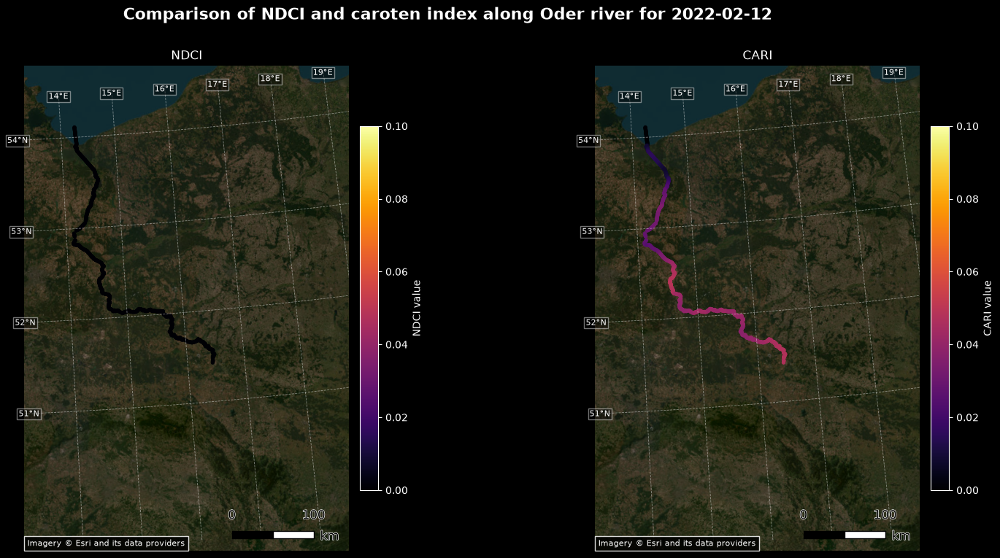

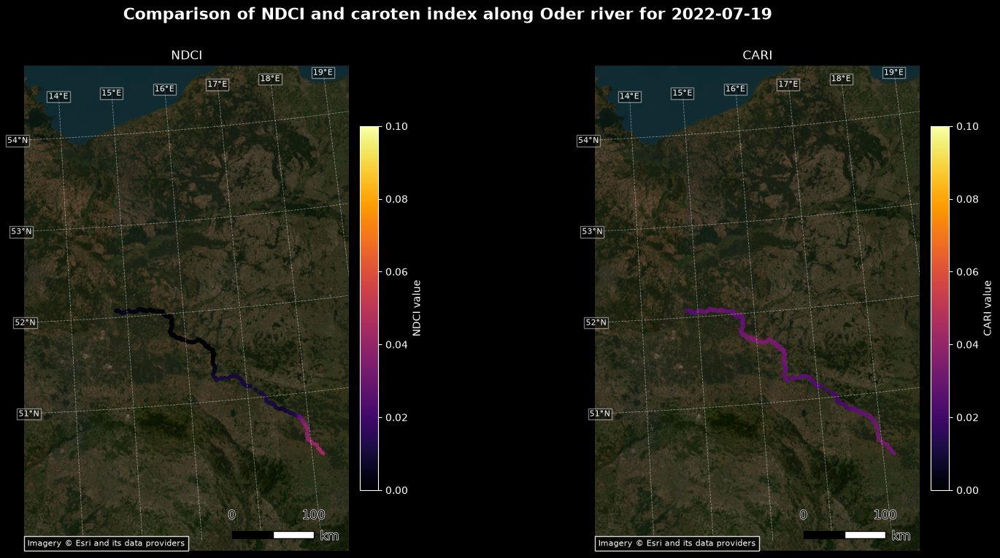

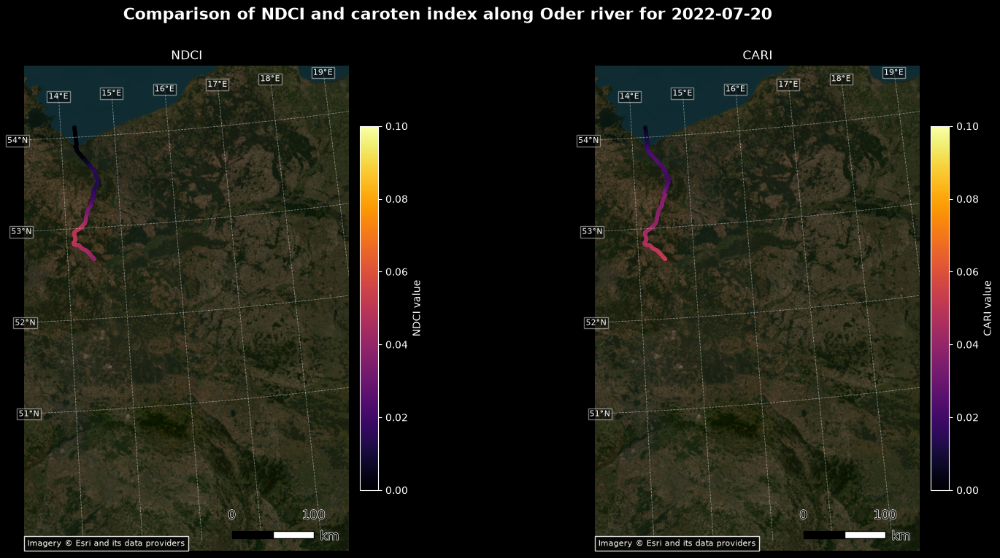

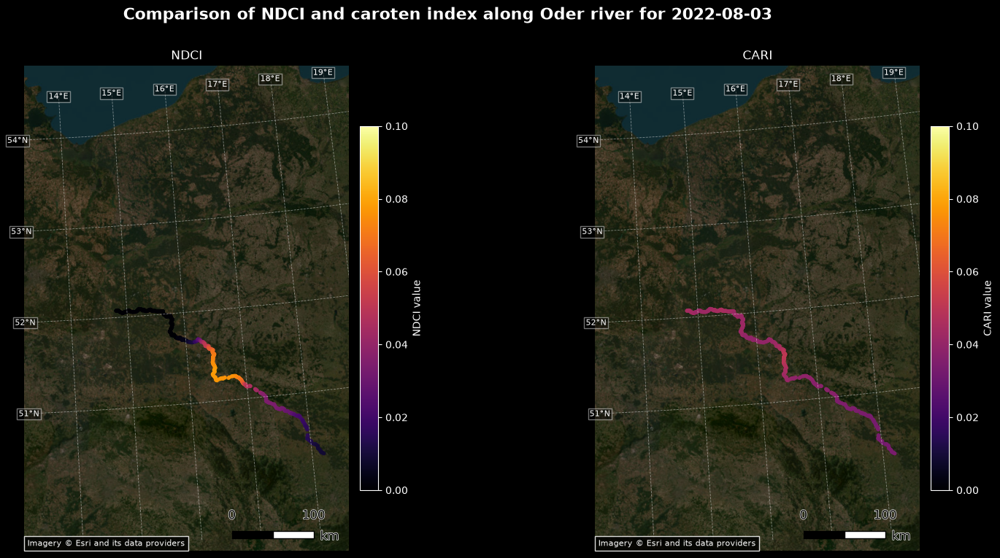

...

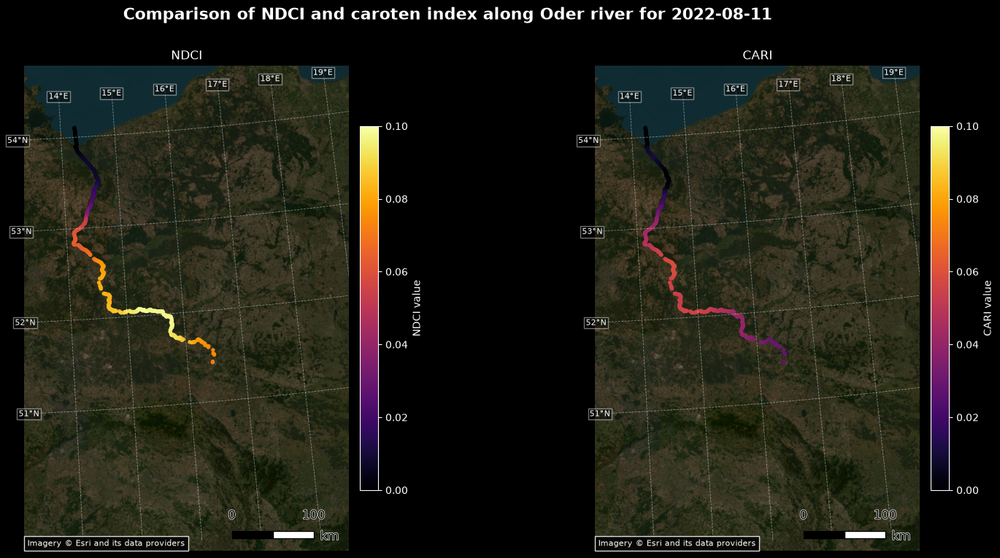

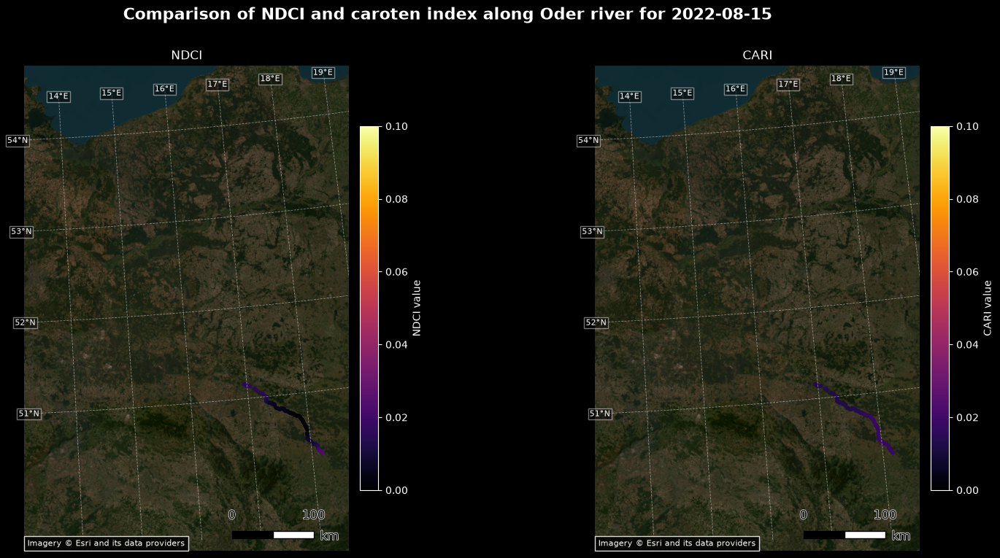

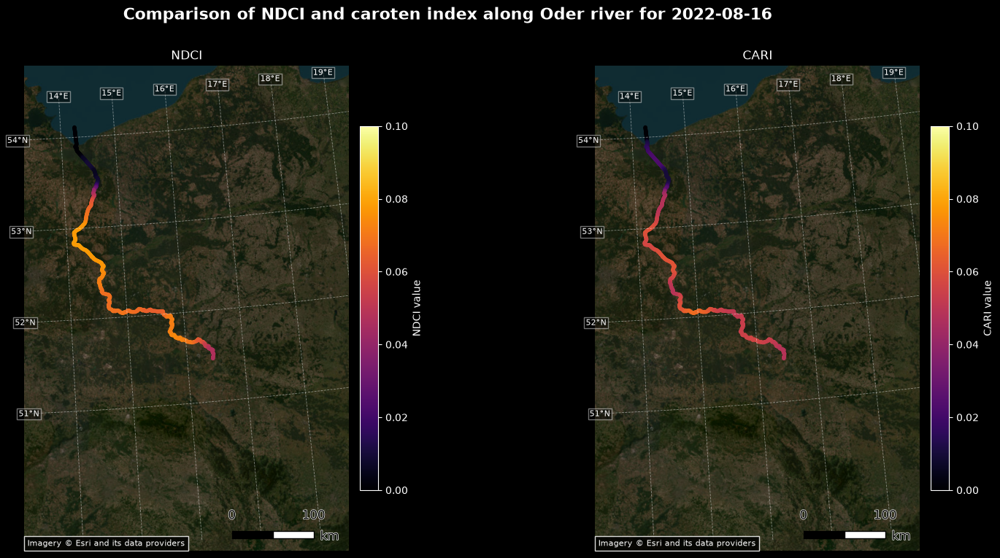

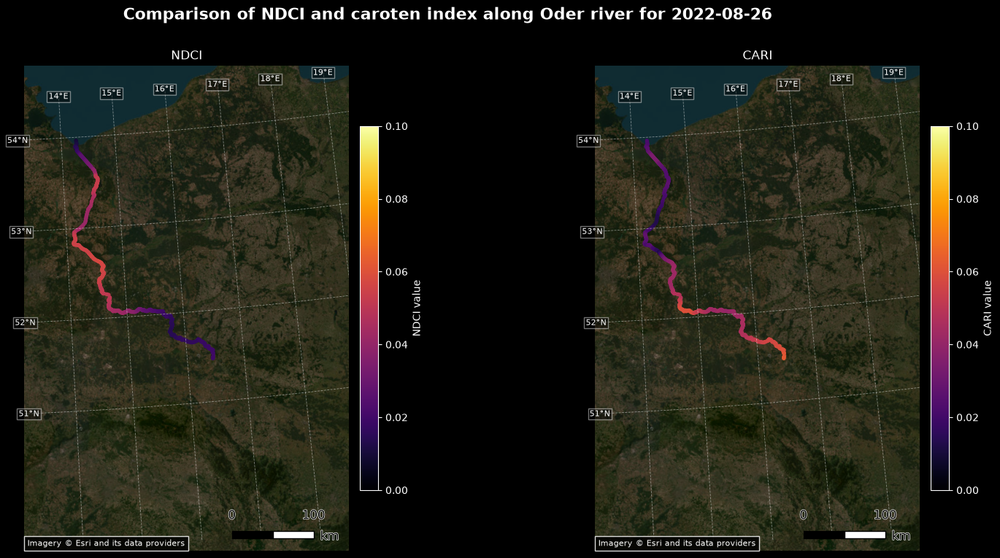

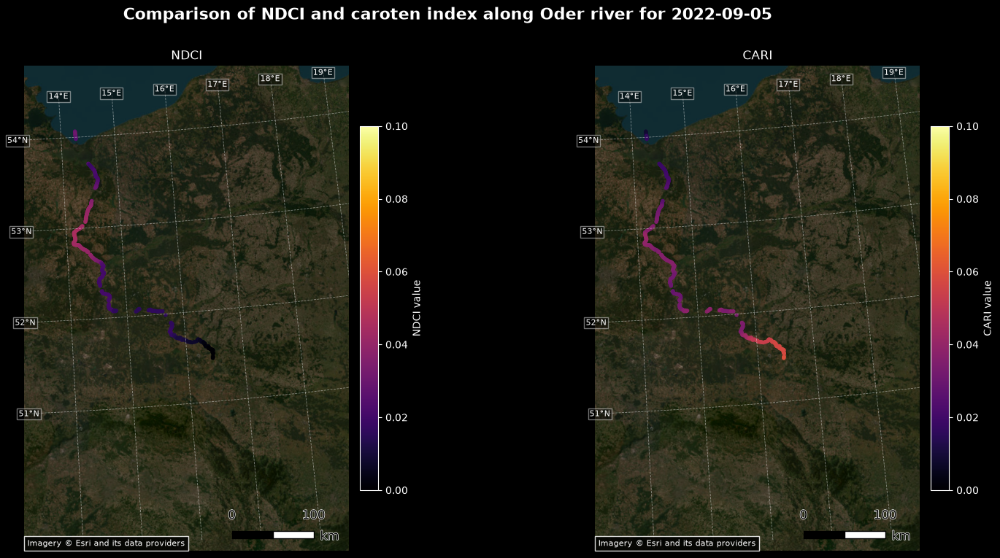

In [7]:
for date in sorted(profiles.keys()):
    profile = profiles[date][::50]
    ndci_median = calculate_ndci(profile=profile, median_window=51)
    cari_median = calculate_cari(profile=profile, median_window=51)
    year, month, day = date[0:4], date[4:6], date[6:8]

    fig, (ax1, ax2) = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(16, 8))
    fig.tight_layout()
    fig.subplots_adjust(top=0.88)
    # fig.subplots_adjust(top=0.8)
    fig, ax1 = plot_background_map(
        title=f"NDCI",
        limits=(13.0, 49.5, 19.5, 54.5),
        target_crs=MAP_CRS,
        fig_ax=(fig, ax1)
    )

    fig, ax2 = plot_background_map(
        title=f"CARI",
        limits=(13.0, 49.5, 19.5, 54.5),
        target_crs=MAP_CRS,
        fig_ax=(fig, ax2)
    )

    fig.suptitle(
        f"Comparison of NDCI and caroten index along Oder river for {year}-{month}-{day}",
        fontsize=16,
        fontweight="bold",
        # y=0.98
    )

    samples_ndci_gdf = gpd.GeoDataFrame(
        ndci_median,
        geometry=gpd.points_from_xy(profile["x"], profile["y"]),
        crs=MAP_CRS,
    )

    samples_cari_gdf = gpd.GeoDataFrame(
        cari_median,
        geometry=gpd.points_from_xy(profile["x"], profile["y"]),
        crs=MAP_CRS,
    )

    cmap = plt.colormaps["inferno"]
    norm = Normalize(vmin=0, vmax=0.1)

    samples_ndci_gdf.plot(
        ax=ax1,
        column=0,
        cmap=cmap,
        norm=norm,
        markersize=15,
        marker="o",
        edgecolor="none",
        alpha=0.95,
    )

    samples_cari_gdf.plot(
        ax=ax2,
        column=0,
        cmap=cmap,
        norm=norm,
        markersize=15,
        marker="o",
        edgecolor="none",
        alpha=0.95,
    )

    colourbar1 = fig.colorbar(
        plt.cm.ScalarMappable(norm=norm, cmap=cmap),
        ax=ax1,
        pad=0.02,
        shrink=0.75,
    )

    colourbar2 = fig.colorbar(
        plt.cm.ScalarMappable(norm=norm, cmap=cmap),
        ax=ax2,
        pad=0.02,
        shrink=0.75,
    )

    colourbar1.set_label("NDCI value")
    colourbar2.set_label("CARI value")
    plt.show()


### Caroten index

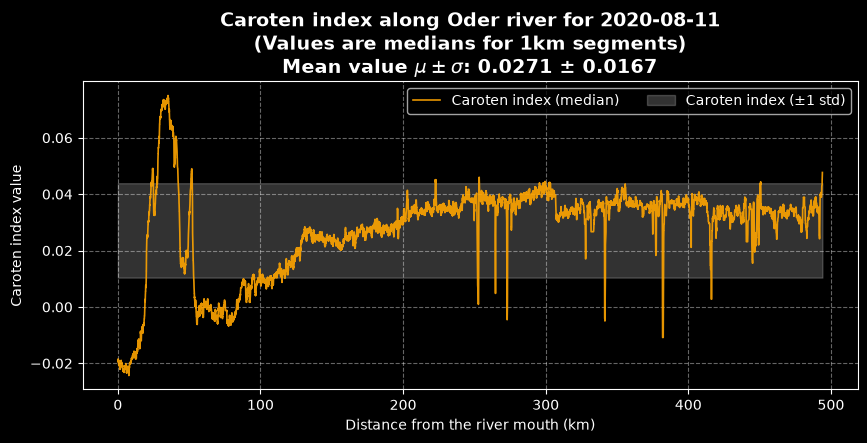

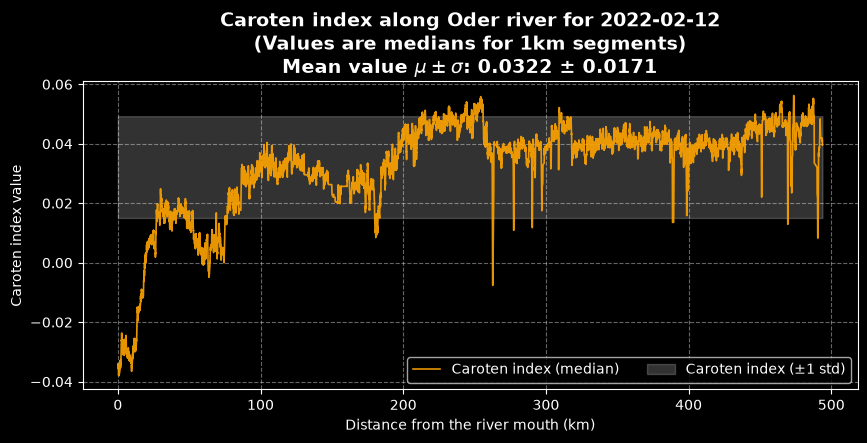

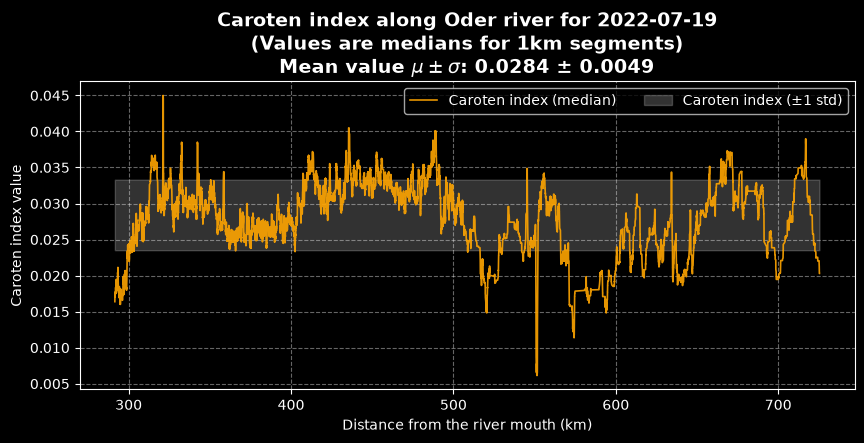

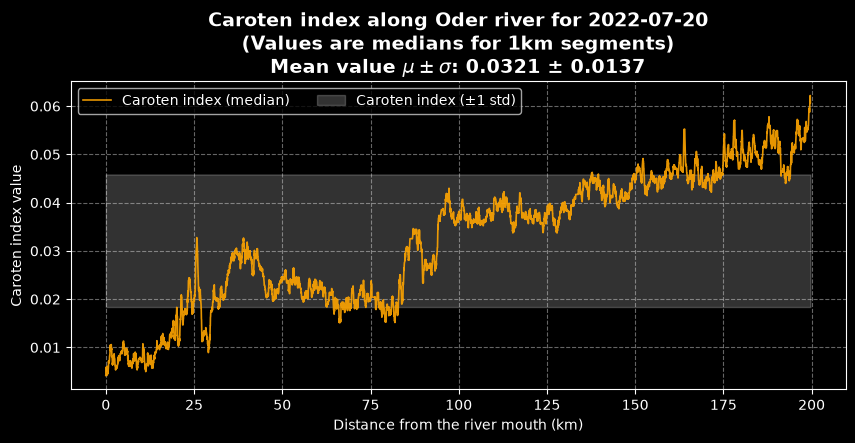

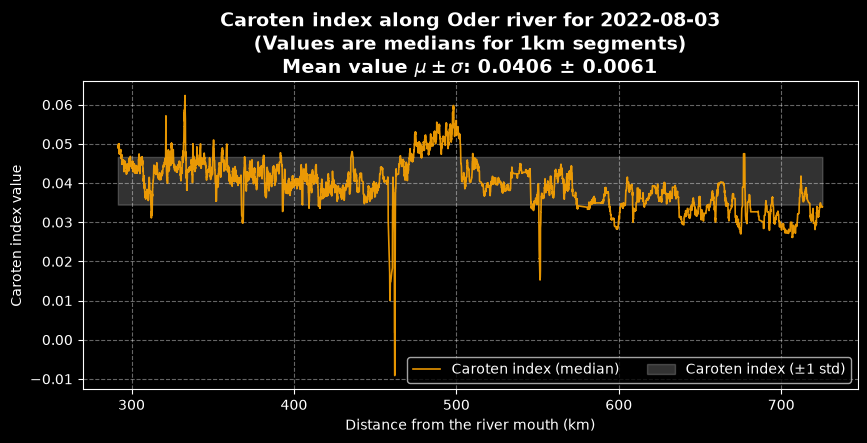

...

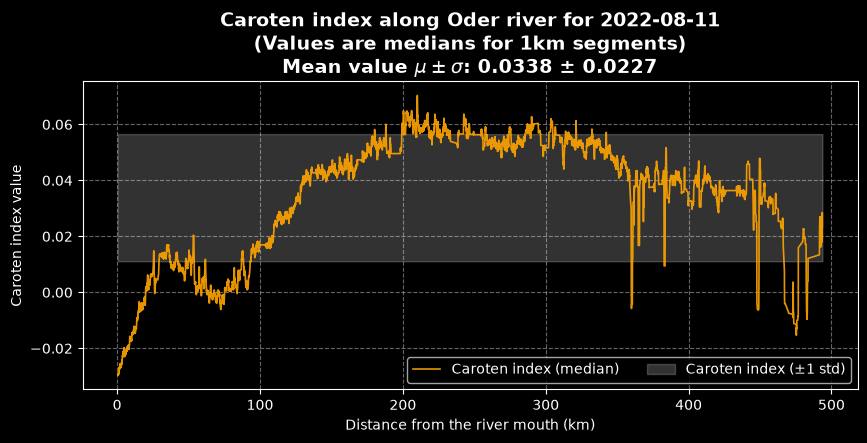

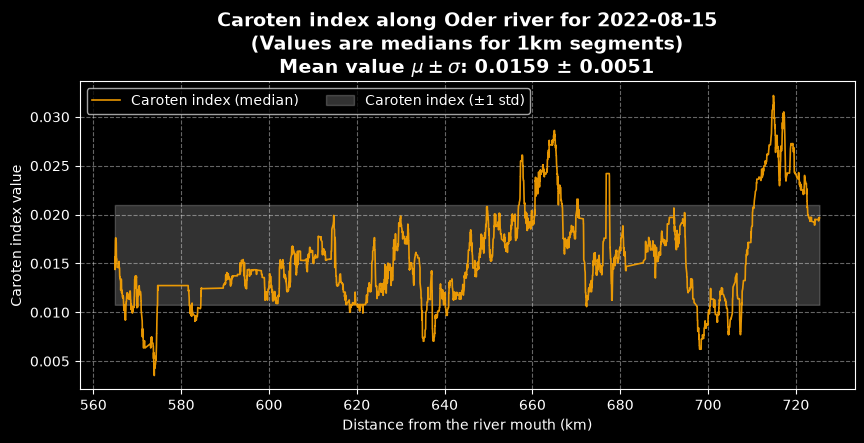

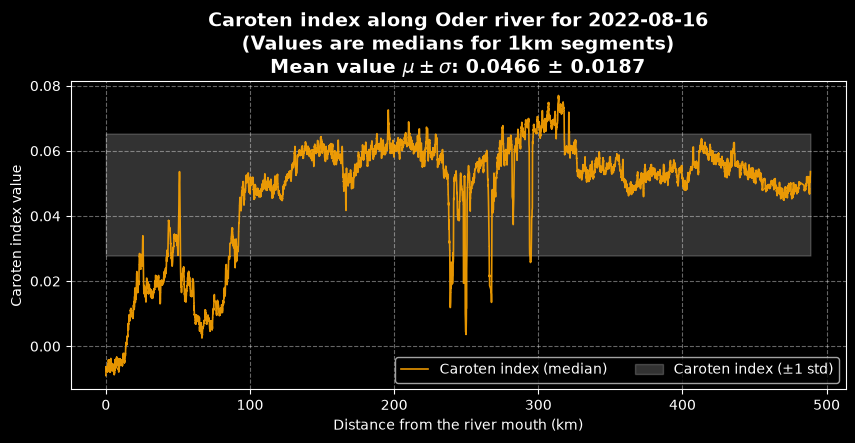

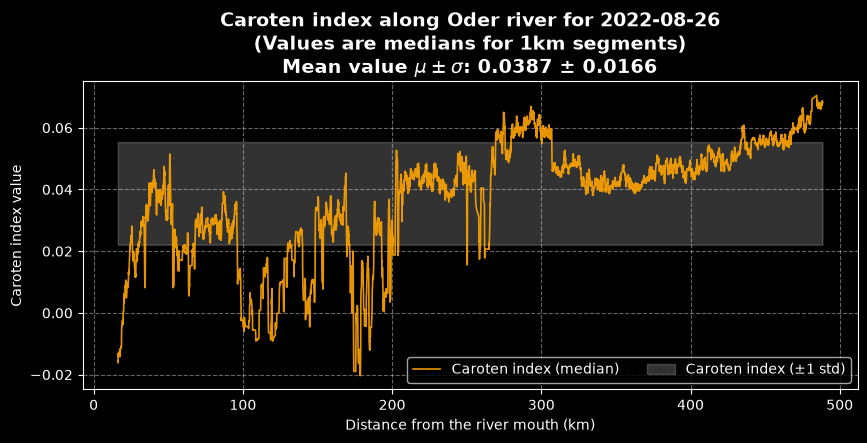

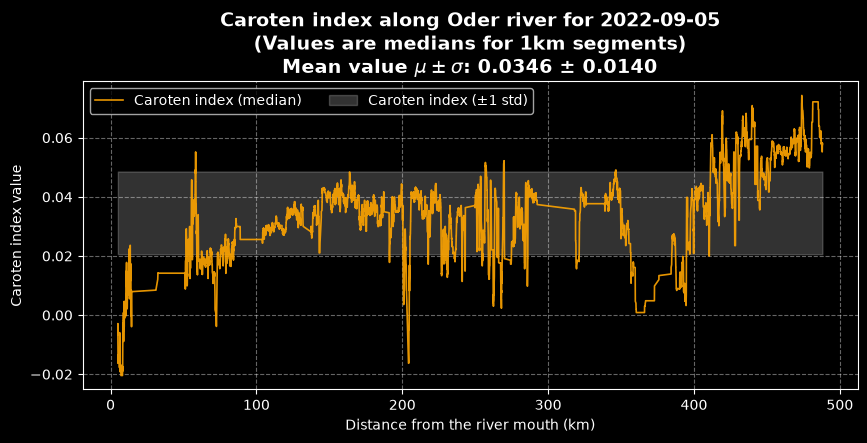

In [6]:
for date in sorted(profiles.keys()):
    profile = profiles[date]
    year, month, day = date[0:4], date[4:6], date[6:8]

    fig, ax = plt.subplots(figsize=(10, 4))
    cari_median = calculate_cari(profile=profile, median_window=51)
    cari_mean = np.mean(cari_median)
    cari_std = np.std(cari_median)

    ax.plot(
        profile["distance_km"],
        cari_median,
        label="Caroten index (median)",
        color="orange",
        linewidth=1.2,
        alpha=0.9
    )

    ax.fill_between(
        profile["distance_km"],
        cari_mean - cari_std,
        cari_mean + cari_std,
        color="white",
        alpha=0.2,
        label="Caroten index (±1 std)"
    )

    ax.set_title(
        "Caroten index along Oder river for " + f"{year}-{month}-{day}\n(Values are medians for 1km segments)" +
        "\nMean value $\\mu\\pm\\sigma$: " + f"{cari_mean:.4f} ± {cari_std:.4f}",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Distance from the river mouth (km)")
    ax.set_ylabel("Caroten index value")
    # ax.set_ylim(-0.02, 0.15)

    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(ncols=2)

    plt.show()